In [125]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
# ====================== 配置区（改这里即可） ======================
DATA_MODE = "simulate"              # "simulate" 或 "paperdata"
USE_MATLAB_PARAMS = True            # True=复现 demo.m 的 matlab 参数; False=python 默认

if DATA_MODE == "simulate":
    SRC          = r"E:\CodingProj\Data\Simulated_Datasets\simulation_1000f_0p10s_simple_circles_ecl_10pps.tif"
    GAIN, OFFSET = 33.448, 1893.68   # 相机换算（光子）
    PIXEL_NM     = 106.7              # nm/px
    CROP         = (0, 255)
    FRAME_SEL    = (10, 990)
    RIED_FRAMES  = 200
    SHOW_PROFILE = True              # simulate: 展示截面 profile + GT 对比
    GT_PATH      = r"E:\CodingProj\Data\Simulated_Datasets\simulation_1000f_0p10s_simple_circles_ecl_10pps_gt_gauss_sresx16.tif"
else:  # paperdata
    SRC          = r"E:\CodingProj\Data\RIED\Raw data ECL_Fig2h.tif"
    GAIN, OFFSET = 1.0, 0.0          # 保持 ADU（对齐 matlab 直接处理 ADU）
    PIXEL_NM     = 160.0             # 对齐 demo.m 的 pixel=160
    CROP         = (0, 442)
    FRAME_SEL    = (1, 100)
    RIED_FRAMES  = 99
    SHOW_PROFILE = False             # paperdata: 不展示 profile / GT
    GT_PATH      = ""

# RIED 算法参数
if USE_MATLAB_PARAMS:
    NA, WAVELENGTH = 1.42, 517.0
    SUBFACTOR, FIDELITY, SPARSITY, ITER2 = 0.0, 150.0, 5.0, 5
    PSF_SIZE = 129                   # kernel.m: n>=129 -> nn=64 -> 129×129
else:
    NA, WAVELENGTH = 1.49, 680.0
    SUBFACTOR, FIDELITY, SPARSITY, ITER2 = 0.0, 50.0, 0.2, 5
    PSF_SIZE = 66

# matlab 超分辨对比（paperdata 才有 matlab 输出）
MATLAB_DIR = r"E:\CodingProj\Data\RIED" if DATA_MODE == "paperdata" else ""
TIRF_PATTERN = "*tirf*.tif*"

# ====================== 包导入 ======================
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import scipy.ndimage
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.aspect"] = "equal"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 110

from smlm.io import load_raw
from smlm import viz
from smlm.viz import show_frames
from smlm.camera import sCMOS
from smlm.imgprocess import (Pipeline, Crop, SelectFrames, BleachCorrect,
                             Dehotpixel, FourierUpsample, GaussianFilter, RL3D,
                             SparseDeconv, CumulantSofit, RiedSofit, scalar_psf,
                             TemporalMean)
from smlm.imgprocess.viz import plot_sofi, line_profile

print("配置:", DATA_MODE, "| matlab 参数:", USE_MATLAB_PARAMS, "| 源:", os.path.basename(SRC))

配置: simulate | matlab 参数: True | 源: simulation_1000f_0p10s_simple_circles_ecl_10pps.tif


## Load Raw

In [20]:
# 加载数据（SRC 见顶部配置）
raw = load_raw(SRC)
print(raw.data.shape, raw.n_frames, raw.em_gain, raw.exposure_time)

(1000, 256, 256) 1000 None None


In [21]:
# camera 层转光子（GAIN/OFFSET 见顶部配置；paperdata 用 gain=1/offset=0 保持 ADU）
H, W = raw.data.shape[1:]            # 视场尺寸 (H, W)
gain_map   = np.full((H, W), GAIN)      # 常数增益图
offset_map = np.full((H, W), OFFSET)    # 常数暗电平图

cam = sCMOS(gain_map=gain_map, offset_map=offset_map)
image = cam.process(raw, pixel_size=PIXEL_NM)

## Preprocessing

In [22]:
# 预处理: 裁剪 ROI + 选帧（CROP / FRAME_SEL 见顶部配置）
prep = Pipeline(Crop(y=CROP, x=CROP),
                SelectFrames(start=FRAME_SEL[0], stop=FRAME_SEL[1]))
stack = prep(image)

<Axes: title={'center': 'avg of 10 frame(s)'}, xlabel='x (px)', ylabel='y (px)'>

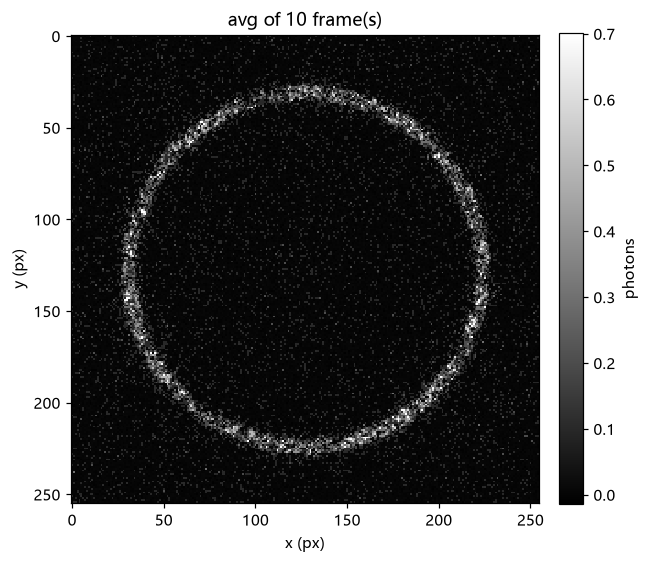

In [23]:
from smlm.viz import show_frames
import numpy as np
show_frames(stack=stack, frames=np.arange(10))

## 代表性像素时间 trace（背景 vs 信号）

在看超分辨结果前，先确认数据的**涨落特征**：背景像素的时间轨迹应贴近平稳基线，
信号（闪烁/burst）像素则出现离散上冲——这是 SOFI/RIED 能提取"涨落"信号的前提。
下面各取 4 条背景与信号像素的 trace，分两张图画。

背景像素: [(12, 95)]
信号像素(按 peak 数取前 N): [('(47,186)', 199)]


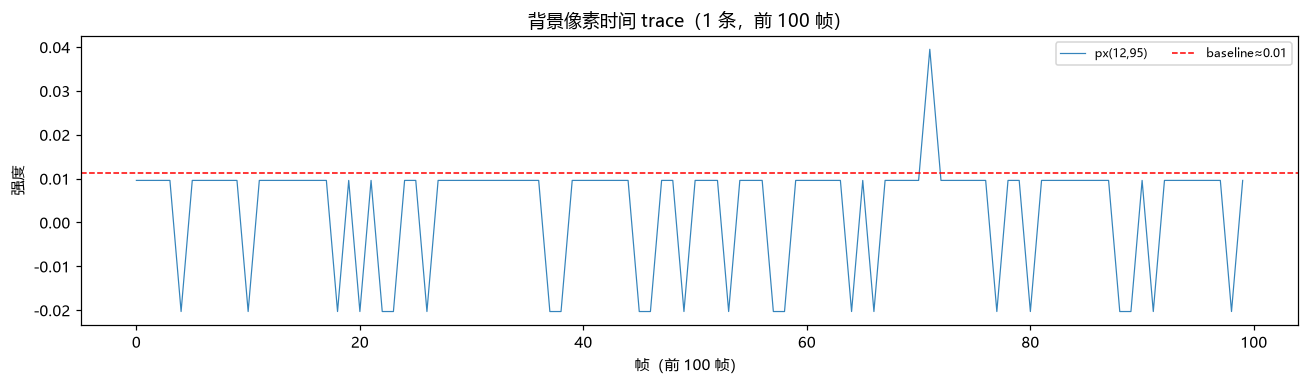

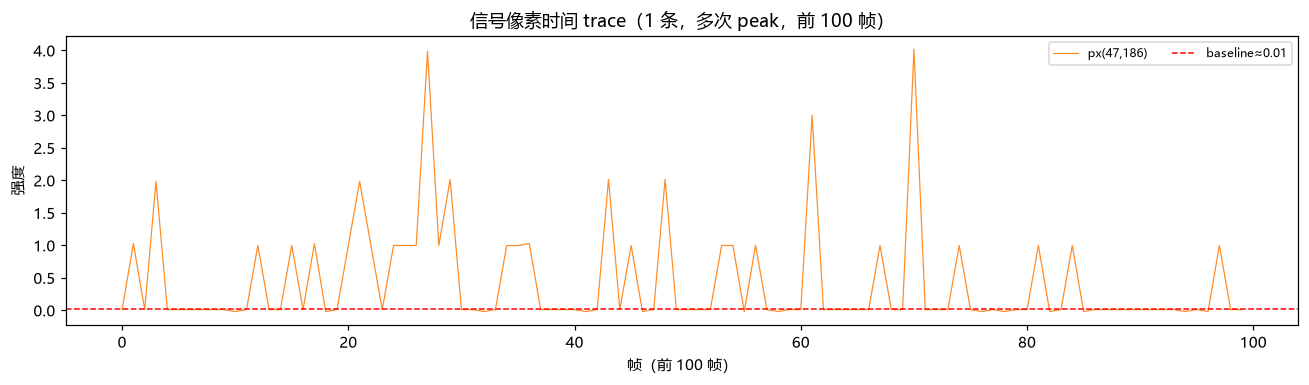

In [25]:
# 代表性像素时间 trace：背景区 vs 信号区（各 N 条，两张图；统一显示前 T_SHOW 帧）
from scipy.signal import find_peaks

N = 1                                   # 每类 trace 条数
M = 300                                 # 信号候选池大小（先按方差粗筛）
T_SHOW = 100                            # 统一显示帧数（前 100 帧）
data = stack.data.astype(np.float64)    # (T,H,W) 光子/ADU
dshow = data[:T_SHOW]                   # 只显示前 100 帧（peak 计数仍用全栈）
mu, var = data.mean(0), data.var(0)
base = float(np.median(mu))             # 全局基线（时间均值中位）

# ---- 背景：方差最小的 N 个像素 ----
order = np.argsort(var, axis=None)
rows, cols = np.unravel_index(order, var.shape)
bg = list(zip(rows[:N].tolist(), cols[:N].tolist()))

# ---- 信号：从方差最大的 M 个候选中，挑"多次 peak（多次闪烁/burst）"的 N 个 ----
cand = list(zip(rows[-M:].tolist(), cols[-M:].tolist()))[::-1]


def _n_peaks(yy, xx):
    """统计该像素时间轨迹的上冲峰数（基线 + 2×稳健噪声之上、相距≥3 帧算独立峰）。"""
    tr = data[:, yy, xx]
    med = float(np.median(tr))
    mad = float(np.median(np.abs(tr - med)))
    thr = med + 2 * (1.4826 * mad + 1e-9)
    pk, _ = find_peaks(tr, height=thr, distance=3)
    return len(pk)


scored = sorted(((_n_peaks(yy, xx), (yy, xx)) for (yy, xx) in cand),
                key=lambda t: t[0], reverse=True)
sg = [p for n, p in scored if n >= 2][:N]      # 优先取 peak≥2（多次闪烁）且最多的
if len(sg) < N:                                 # 兜底：不足则取 peak 数最多的
    sg = [p for _, p in scored][:N]

print("背景像素:", bg)
print("信号像素(按 peak 数取前 N):", [(f"({yy},{xx})", n) for n, (yy, xx) in scored[:N]])


def _plot_traces(ax, picks, title, color):
    for (yy, xx) in picks:
        ax.plot(dshow[:, yy, xx], lw=0.8, alpha=0.9, color=color,
                label=f"px({yy},{xx})")
    ax.axhline(base, color='r', ls='--', lw=1, label=f'baseline≈{base:.2f}')
    ax.set_xlabel(f'帧（前 {T_SHOW} 帧）'); ax.set_ylabel('强度')
    ax.set_title(title); ax.legend(fontsize=8, ncol=2)


fig, ax = plt.subplots(figsize=(12, 3.6))
_plot_traces(ax, bg, f'背景像素时间 trace（{len(bg)} 条，前 {T_SHOW} 帧）', 'C0')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.6))
_plot_traces(ax, sg, f'信号像素时间 trace（{len(sg)} 条，多次 peak，前 {T_SHOW} 帧）', 'C1')
plt.tight_layout(); plt.show()

## 传统 SOFI: n 阶累积量

SOFI 对每个像素计算信号的时间累积量：

$$\kappa_m(\mathbf r) \propto \sum_k \varepsilon_k^m\, U^m(\mathbf r - \mathbf r_k)$$

即输出 PSF 是 $U^m$（宽度 $\div\sqrt{m}$）。**阶数越高分辨率越高**。

这里用重构后的 `smlm.imgprocess`：`CumulantSofit` 是 SOFI 核心（`Transform` 子类），上采样通过显式的 `FourierUpsample` 阶段接入 `Pipeline`——所有环节都是 `ImageStack` 进、`ImageStack` 出。

In [155]:
# 加载超分辨 ground truth（仅 simulate 需要; paperdata 无 GT 则自动跳过）
GT_AVAILABLE = bool(GT_PATH) and os.path.exists(GT_PATH)
gt_sres = None
gt_ps = PIXEL_NM / 16                          # ≈6.67 nm/px（与 GT 渲染一致）
if GT_AVAILABLE:
    gt_sres = tifffile.imread(GT_PATH).astype(np.float64)  # (4096, 4096)
    print("GT:", gt_sres.shape, "| 有效像素:", gt_ps, "nm/px | 范围: [%.1f, %.1f]" % (gt_sres.min(), gt_sres.max()))
else:
    print("⚠️ 无 GT（paperdata 或无文件）—— 对比图将不含 GT / 剖面。")


def crop_extent(z, ps, roi_y, roi_x, W0):
    """按宽场像素 ROI 裁剪图像 z，返回 (裁剪块, nm extent)。

    物理坐标以 z 自身网格中心为原点：ext = (left, right, bottom, top) nm。
    各 stage 网格/像素尺寸不同，用各自 s=z.shape[1]/W0 换算出同一物理区域。
    """
    s = z.shape[1] / W0
    y0, y1 = int(roi_y[0] * s), int(roi_y[1] * s)
    x0, x1 = int(roi_x[0] * s), int(roi_x[1] * s)
    c = z[y0:y1, x0:x1]
    h, w = z.shape[:2]
    ext = ((x0 - w / 2) * ps, (x1 - w / 2) * ps,
           (y1 - h / 2) * ps, (y0 - h / 2) * ps)           # left,right,bottom,top (nm)
    return c, ext


def gt_similarity(z):
    """把图像 z 对齐到 GT 网格，返回与 GT 的相似性指标 dict（仅 simulate 用）。

    指标：Pearson r / SSIM / PSNR(dB) / NRMSE。z 与 GT 假设覆盖同一 FOV，
    用 map_coordinates 重采样到 GT 网格（4096²）后比较。
    """
    from skimage.metrics import structural_similarity as ssim

    def _resample(img, n):
        h, w = img.shape
        yy = (np.arange(n) + 0.5) * h / n - 0.5
        xx = (np.arange(n) + 0.5) * w / n - 0.5
        YY, XX = np.meshgrid(yy, xx, indexing="ij")
        return scipy.ndimage.map_coordinates(img, (YY, XX), order=1,
                                             mode="constant", cval=0.0)

    def _norm01(a):
        a = a - a.min(); mx = a.max()
        return a / mx if mx > 0 else a

    def _pearson(a, b):
        a = a - a.mean(); b = b - b.mean()
        return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))

    def _psnr(a01, b01):
        mse = float(np.mean((a01 - b01) ** 2))
        return float(10 * np.log10(1.0 / mse)) if mse > 0 else float('inf')

    a = _resample(np.asarray(z, dtype=np.float64), gt_sres.shape[0])
    an, gn = _norm01(a), _norm01(gt_sres)
    return {"Pearson r": _pearson(a, gt_sres),
            "SSIM": ssim(an, gn, data_range=1.0),
            "PSNR (dB)": _psnr(an, gn),
            "NRMSE": float(np.sqrt(np.mean((an - gn) ** 2)))}

GT: (4096, 4096) | 有效像素: 6.66875 nm/px | 范围: [0.0, 131.0]


In [156]:
# 跳过光漂白校正（数据已平稳）; 若需校正可改回: stack_bc = BleachCorrect("mono_exp")(stack)
stack_bc = stack
print("stack_bc:", stack_bc.data.shape, "| pixel_size:", stack_bc.pixel_size, "nm/px")

stack_bc: (980, 255, 255) | pixel_size: 106.7 nm/px


In [157]:
# 传统 n 阶累积量 SOFI: Pipeline(FourierUpsample(2), CumulantSofit(order=m))
orders = [2, 3]
sofi_res = {}
for m in orders:
    img = Pipeline(FourierUpsample(2, taper=False),
                   CumulantSofit(order=m, subseq=250))(stack_bc)
    sofi_res[m] = img.data[0]
    print(f"order {m}: {img.data.shape}  range [{img.data.min():.3g}, {img.data.max():.3g}]")

order 2: (1, 510, 510)  range [-2.15, 820]
order 3: (1, 510, 510)  range [-3.27e+03, 5.29e+03]


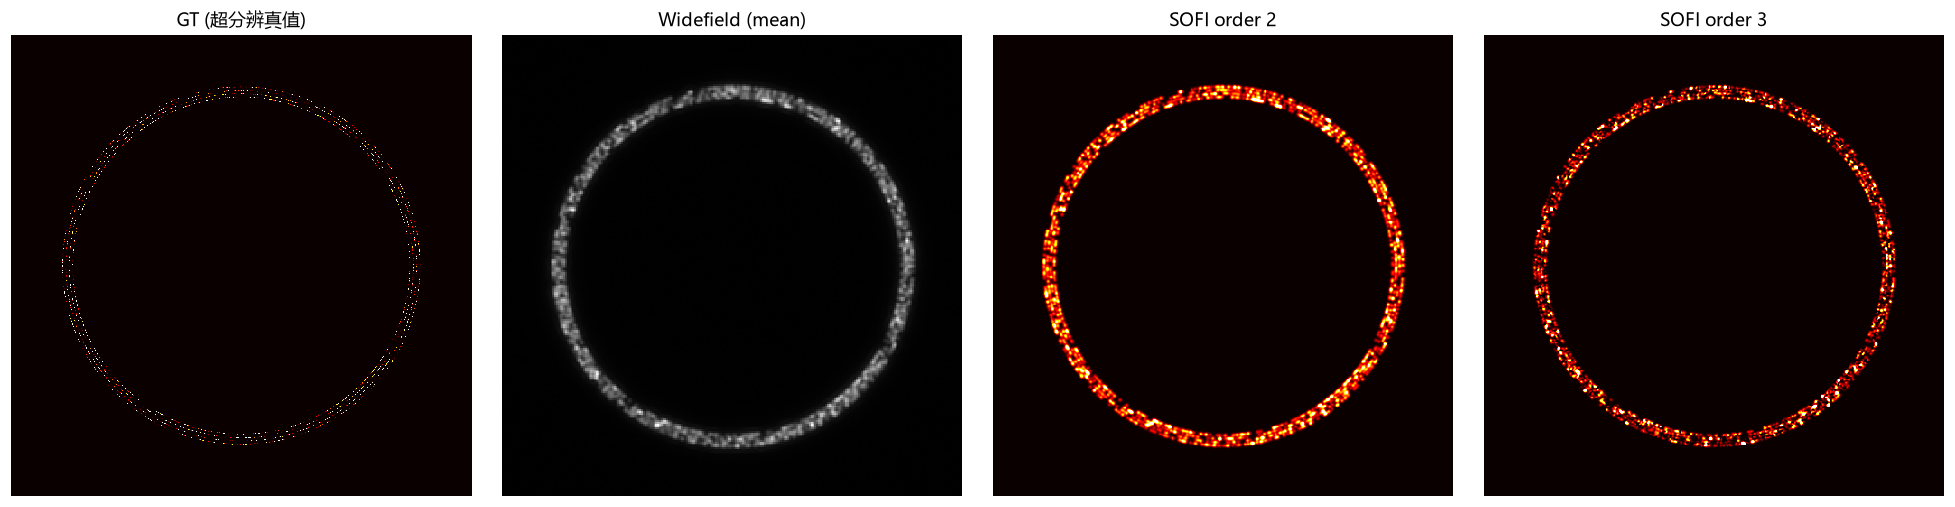

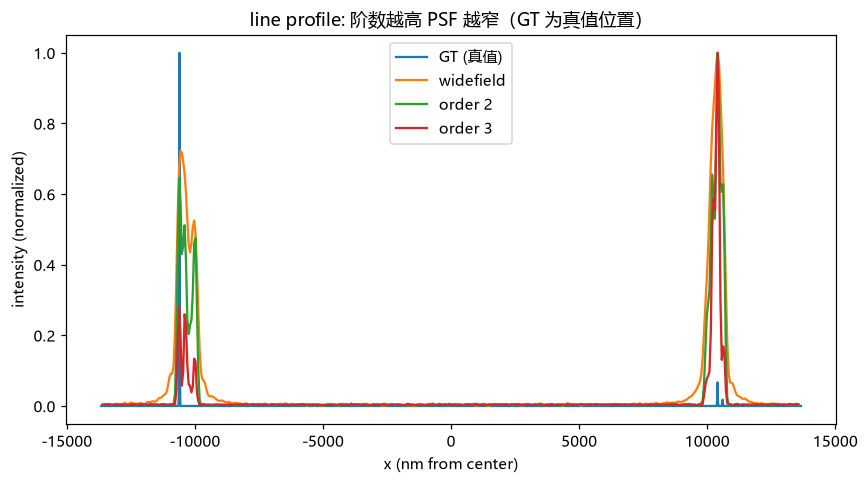

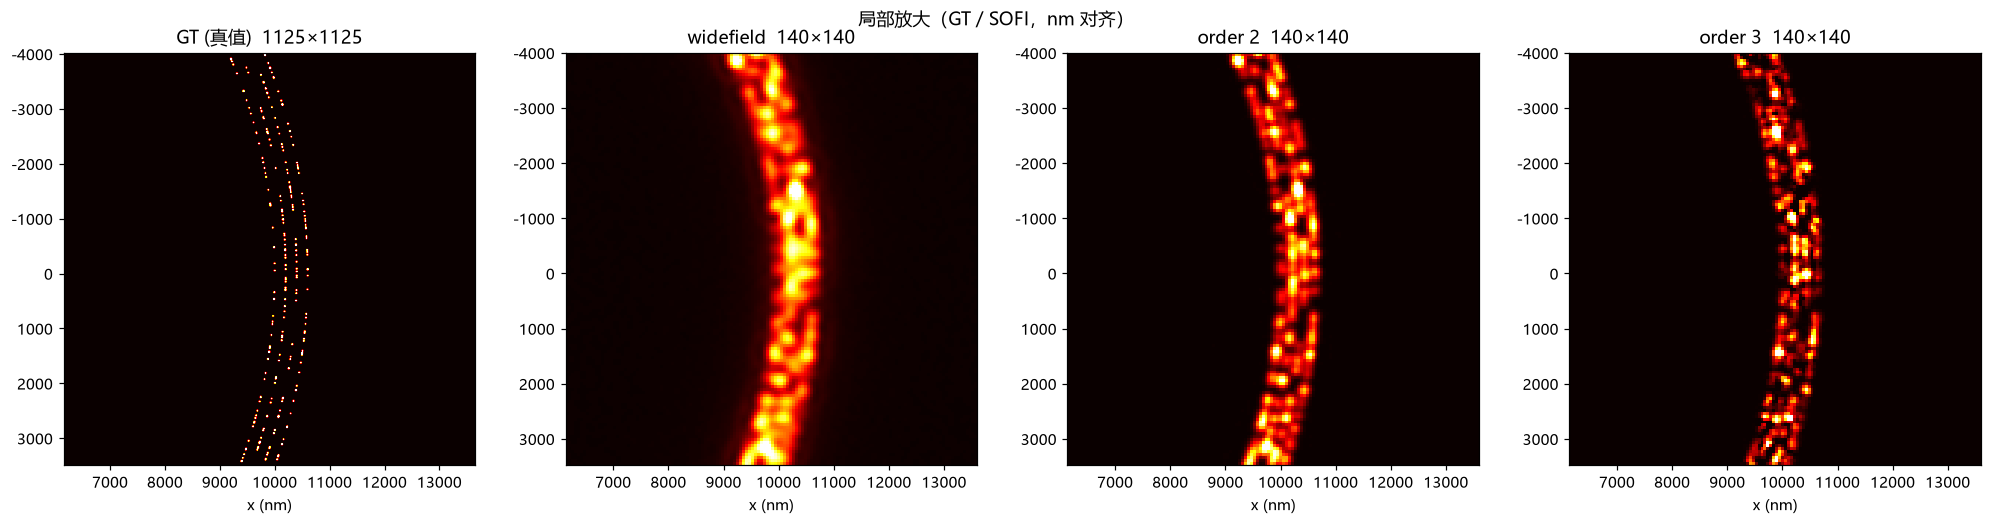

=== 与 GT 的相似性（SOFI，simulate）===
方法               Pearson r    SSIM  PSNR(dB)   NRMSE
widefield           0.2404   0.024     18.29  0.1218
SOFI order 2        0.2722   0.864     24.99  0.0563
SOFI order 3        0.2185   0.001      8.29  0.3851


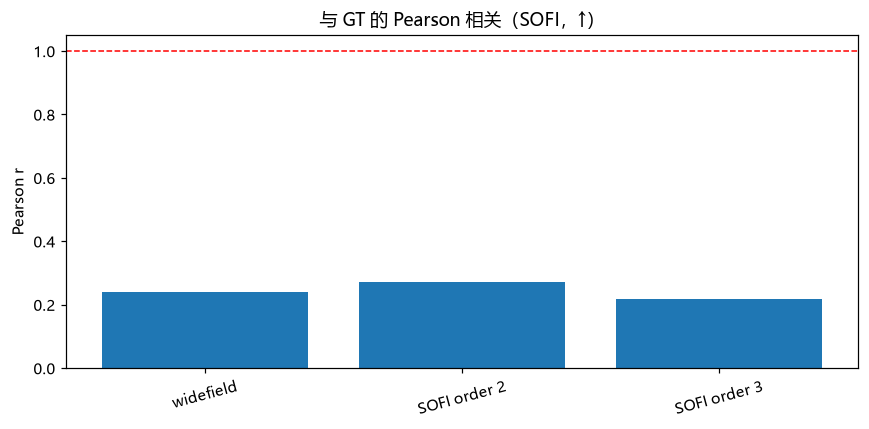

In [158]:
# 传统 SOFI 对比（simulate 显示 GT + 截面 profile；paperdata 仅并排 + 中央放大）
ps_up = stack_bc.pixel_size / 2                       # 2× 上采样后的有效像素 (nm)
wf2 = FourierUpsample(2, taper=False)(stack_bc).data.mean(0)     # 对齐到 2× 网格

ncol = (2 if GT_AVAILABLE else 1) + len(orders)
fig, axes = plt.subplots(1, ncol, figsize=(4.5 * ncol, 4.5))
i0 = 0
if GT_AVAILABLE:
    axes[0].imshow(gt_sres, cmap="hot", vmax=np.percentile(gt_sres, 99.8),
                   interpolation="nearest", aspect="equal")
    axes[0].set_title("GT (超分辨真值)"); axes[0].axis("off")
    i0 = 1
axes[i0].imshow(stack_bc.data.mean(0), cmap="gray", interpolation="nearest", aspect="equal")
axes[i0].set_title("Widefield (mean)"); axes[i0].axis("off")
for ax, m in zip(axes[i0 + 1:], orders):
    plot_sofi(sofi_res[m], ax=ax, title=f"SOFI order {m}")
plt.tight_layout(); plt.show()

# 线剖面（仅 simulate 展示, x 轴 = 距中心 nm）
if SHOW_PROFILE:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if GT_AVAILABLE:
        line_profile(gt_sres, row=gt_sres.shape[0] // 2, ax=ax, label="GT (真值)", pixel_size=gt_ps)
    line_profile(wf2, row=wf2.shape[0] // 2, ax=ax, label="widefield", pixel_size=ps_up)
    for m in orders:
        line_profile(sofi_res[m], row=sofi_res[m].shape[0] // 2, ax=ax,
                     label=f"order {m}", pixel_size=ps_up)
    ax.set_title("line profile: 阶数越高 PSF 越窄" + ("（GT 为真值位置）" if GT_AVAILABLE else "")); ax.legend()
    plt.tight_layout(); plt.show()

# 局部放大（simulate: 右弧环壁; paperdata: 中央 50% 区域），统一按 nm 物理坐标对齐
W0 = stack_bc.data.shape[1]
H0 = stack_bc.data.shape[0]
if DATA_MODE == "simulate":
    roi_y, roi_x = (90, 160), (185, 255)
else:
    roi_y, roi_x = (H0 // 4, 3 * H0 // 4), (W0 // 4, 3 * W0 // 4)

sofi_imgs = []
if GT_AVAILABLE:
    sofi_imgs.append(("GT (真值)", *crop_extent(gt_sres, gt_ps, roi_y, roi_x, W0)))
sofi_imgs += [("widefield", *crop_extent(wf2, ps_up, roi_y, roi_x, W0))] + \
             [(f"order {m}", *crop_extent(sofi_res[m], ps_up, roi_y, roi_x, W0)) for m in orders]
fig, axes = plt.subplots(1, len(sofi_imgs), figsize=(4.6 * len(sofi_imgs), 4.6))
for ax, (nm, c, ext) in zip(axes, sofi_imgs):
    v = np.percentile(c, 99.8)
    ax.imshow(np.clip(c, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=ext)
    ax.set_title(f"{nm}  {c.shape[0]}×{c.shape[1]}"); ax.set_xlabel("x (nm)")
fig.suptitle("局部放大（GT / SOFI，nm 对齐）")
plt.tight_layout(); plt.show()

# 与 GT 的相似性评估（仅 simulate）
if SHOW_PROFILE and GT_AVAILABLE:
    print("=== 与 GT 的相似性（SOFI，simulate）===")
    rows = [("widefield", wf2)] + [(f"SOFI order {m}", sofi_res[m]) for m in orders]
    sim = {n: gt_similarity(z) for n, z in rows}
    print(f"{'方法':<16}{'Pearson r':>10}{'SSIM':>8}{'PSNR(dB)':>10}{'NRMSE':>8}")
    for n in sim:
        print(f"{n:<16}{sim[n]['Pearson r']:>10.4f}{sim[n]['SSIM']:>8.3f}"
              f"{sim[n]['PSNR (dB)']:>10.2f}{sim[n]['NRMSE']:>8.4f}")
    fig, ax = plt.subplots(figsize=(8, 4))
    xn = list(sim)
    ax.bar(np.arange(len(xn)), [sim[n]["Pearson r"] for n in xn], color="C0")
    ax.axhline(1, color='r', ls='--', lw=1)
    ax.set_xticks(np.arange(len(xn))); ax.set_xticklabels(xn, rotation=15)
    ax.set_ylabel("Pearson r"); ax.set_title("与 GT 的 Pearson 相关（SOFI，↑）")
    plt.tight_layout(); plt.show()

## RIED: 0-lag 二阶累积量 —— 逐步加长 pipeline

RIED 的核心是**熵加权相关** `EC = 熵图 × 交叉累积量`：

- **交叉累积量**（`xc_cumulant`）：0-lag 二阶统计量，用"偏移均值差 × 相邻像素乘积"
  提取涨落信息，并生成 **2× 虚拟像素网格**；
- **熵图**（`entromap`）：2×2 邻域时间轨迹的交叉熵，用于识别真正的发光体/抑制背景。

下面**逐步加长 pipeline**，每一级都在上一级基础上追加一步，并记录尺寸演进
（裁剪后视场为 255×255，每级 2× → 255 → 510 → 1020）：

| Stage | 追加内容 | 目的 | 输出尺寸 / 像素 |
|---|---|---|---|
| 宽场 | 时间均值 | 原始对照 | 255×255 / 106.6 nm |
| P1 | 高斯预滤波 | 抑制高频采样噪声 | 255×255 / 106.6 nm |
| P2 | + 傅里叶上采样 ×2 → RL3D 预反卷积 | 加密网格 + 增强涨落 | 510×510 / 53.3 nm |
| P3 | + 0-lag 二阶累积量 (xc_cumulant) | 提取涨落信息（分辨率提升核心） | 1020×1020 / 26.7 nm |
| P4 | + 熵加权 (entromap × 累积量) | 抑制背景、突出发光体 | 1020×1020 / 26.7 nm |
| P5 | + 后置稀疏反卷积 (split-Bregman TV+L1) | 进一步锐化、去伪影 | 1020×1020 / 26.7 nm |

> **尺寸注意**：各级网格/像素尺寸不同（106.6 → 53.3 → 26.7 nm/px），
> 所以下面所有可视化都按**物理坐标 (nm) 对齐**：ROI 裁剪与线剖面都用
> 各 stage 自身的网格索引换算到同一物理区域，而不是按像素数直接对齐。

In [159]:
# RIED: 0-lag 二阶累积量 —— 逐步加长 pipeline（参数见顶部配置）
ried_stack = Dehotpixel()(SelectFrames(stop=RIED_FRAMES)(stack_bc))   # 短栈 + 热点去除
print("ried_stack:", ried_stack.data.shape, "| pixel:", ried_stack.pixel_size, "nm/px")

stages = {}
# P1: 高斯预滤波（栈 → 取时间均值作为单张对照）
stages["P1: 高斯滤波"] = Pipeline(GaussianFilter(0.7))(ried_stack).data.mean(0)
print("P1:", stages["P1: 高斯滤波"].shape)

# P2: + 傅里叶上采样 ×2 → RL3D 预反卷积
# PSF 用 scalar_psf（Generate_PSF 等价的标量衍射积分），网格像素 = 实际数据像素/2
psf1 = scalar_psf((PSF_SIZE, PSF_SIZE), ried_stack.pixel_size / 2, NA, WAVELENGTH)
stages["P2: +上采样+RL"] = Pipeline(GaussianFilter(0.7),
                                    FourierUpsample(2, taper=False),
                                    RL3D(psf1, iterations=4))(ried_stack).data.mean(0)
print("P2:", stages["P2: +上采样+RL"].shape)

ried_stack: (200, 255, 255) | pixel: 106.7 nm/px
P1: (255, 255)
P2: (510, 510)


In [160]:
# P3: + 0-lag 二阶累积量（xc_cumulant，无熵加权）
stages["P3: +0lag累积量"] = Pipeline(GaussianFilter(0.7),
              FourierUpsample(2, taper=False),
              RL3D(psf1, iterations=4), RiedSofit(subfactor=SUBFACTOR, entropy=False))(ried_stack).data[0]
print("P3:", stages["P3: +0lag累积量"].shape)

P3: (1020, 1020)


In [161]:
# P4: + 熵加权（entromap × xc_cumulant）
stages["P4: +熵加权"] = Pipeline(GaussianFilter(0.7),
              FourierUpsample(2, taper=False),
              RL3D(psf1, iterations=4), RiedSofit(subfactor=SUBFACTOR, entropy=True))(ried_stack).data[0]
print("P4:", stages["P4: +熵加权"].shape)

P4: (1020, 1020)


In [162]:
# P5: + 后置稀疏反卷积（split-Bregman TV+L1，末段 RL）
# RIED 后置 PSF 在更细网格 (pixel/(finter*finter2)/2) 上生成，scalar_psf 同 matlab
psf2 = scalar_psf((PSF_SIZE, PSF_SIZE), ried_stack.pixel_size / 4, NA, WAVELENGTH)
post = SparseDeconv(psf2, fidelity=FIDELITY, sparsity=SPARSITY, iter_bregman=100, iterations=ITER2)
stages["P5: +后置反卷积"] = Pipeline(GaussianFilter(0.7),
              FourierUpsample(2, taper=False),
              RL3D(psf1, iterations=4), RiedSofit(subfactor=SUBFACTOR, entropy=True),
                                     post)(ried_stack).data[0]
print("P5:", stages["P5: +后置反卷积"].shape)

P5: (1020, 1020)


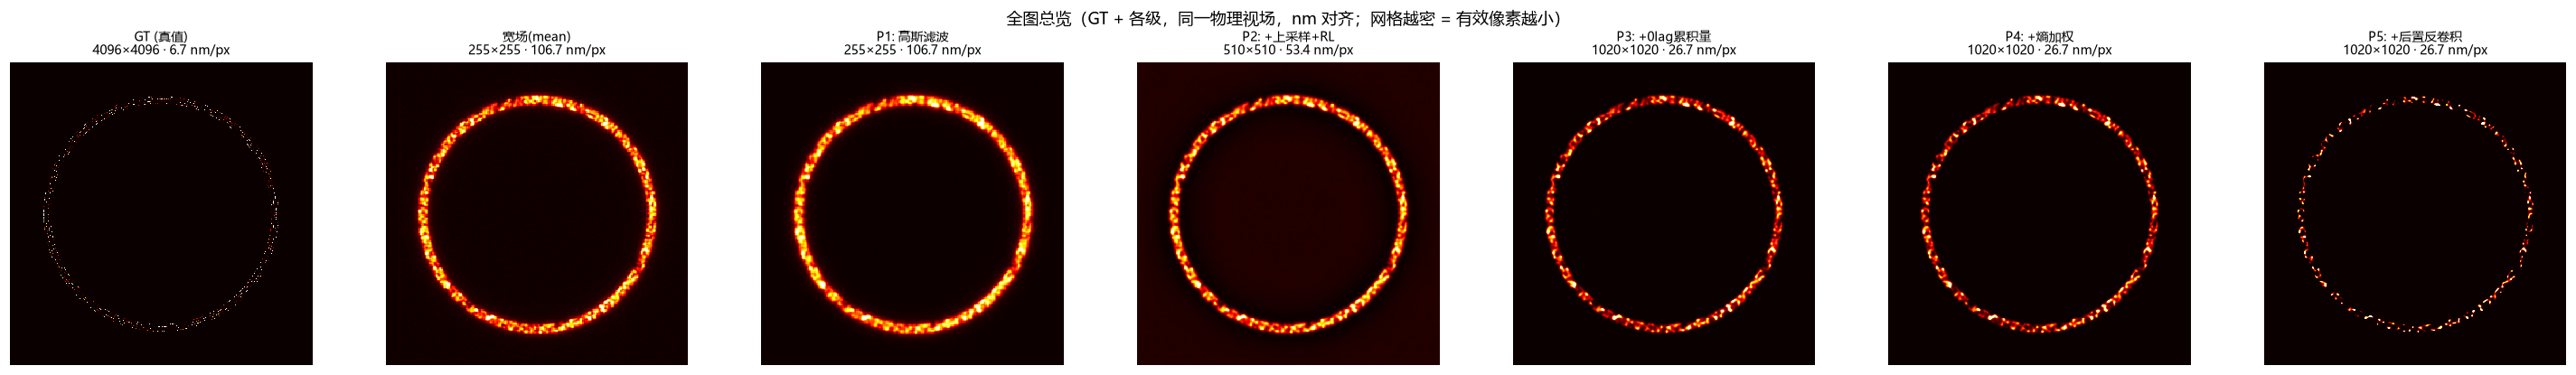

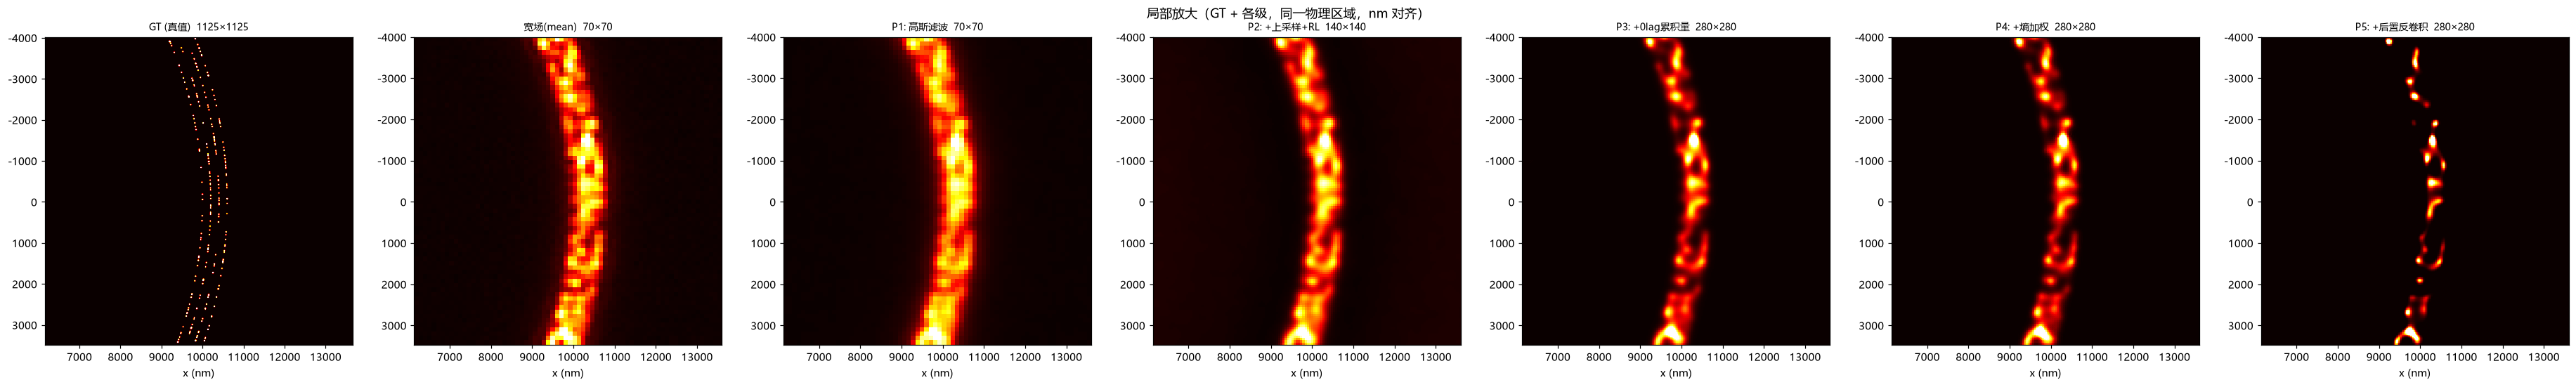

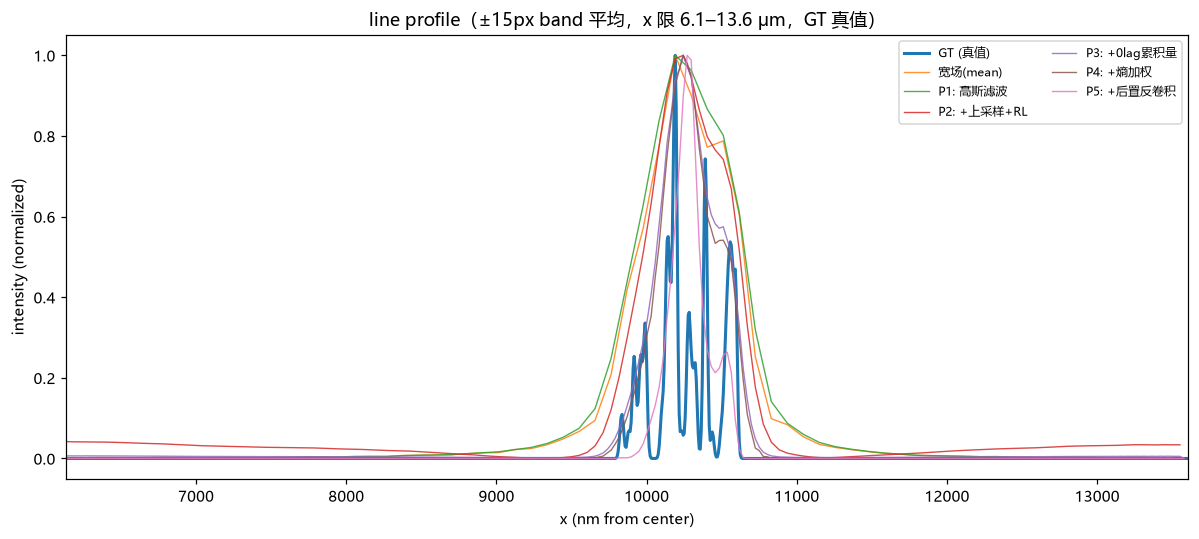

=== 各 stage 与 GT 的相似性（RIED，simulate）===
stage            Pearson r    SSIM  PSNR(dB)   NRMSE
GT (真值)             1.0000   1.000  inf   0.0000
宽场(mean)            0.2244   0.025   18.04  0.1253
P1: 高斯滤波            0.2160   0.018   16.78  0.1449
P2: +上采样+RL         0.2397   0.099   20.90  0.0901
P3: +0lag累积量        0.2471   0.920   28.62  0.0371
P4: +熵加权            0.2464   0.936   30.13  0.0312
P5: +后置反卷积          0.1666   0.977   35.95  0.0159


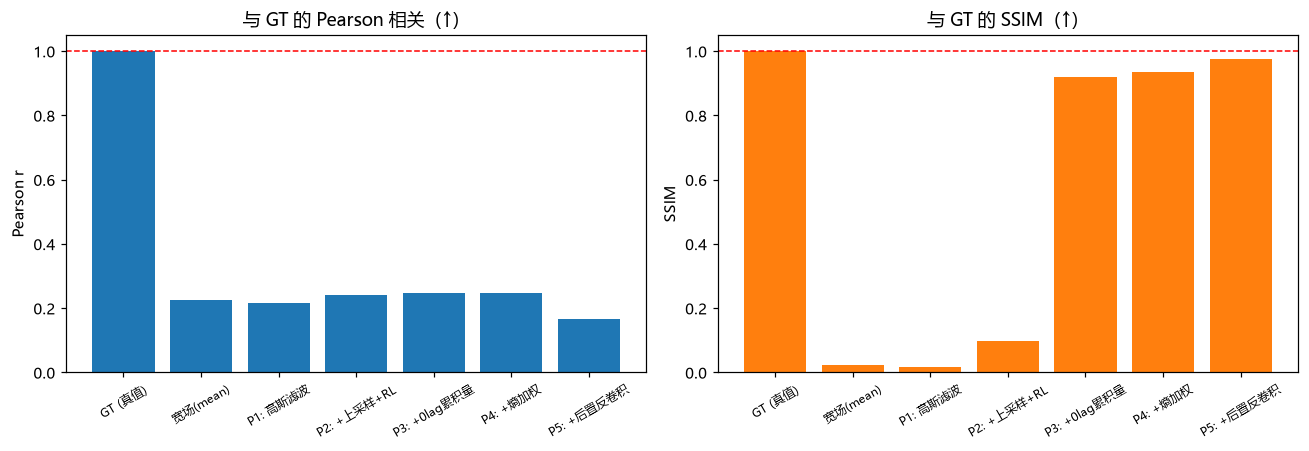

In [163]:
# RIED 对比：全图总览 + 局部放大 + (simulate) 截面 profile + GT + 相似性评估
names = (["GT (真值)"] if GT_AVAILABLE else []) + ["宽场(mean)"] + list(stages)
imgs  = ([gt_sres] if GT_AVAILABLE else []) + [ried_stack.data.mean(0)] + list(stages.values())
W0, H0 = ried_stack.data.shape[1], ried_stack.data.shape[0]
ps_wide = ried_stack.pixel_size
stage_ps = ([gt_ps] if GT_AVAILABLE else []) + \
           [ps_wide * W0 / z.shape[1] for z in (imgs[1:] if GT_AVAILABLE else imgs)]   # 各 stage 有效像素 (nm/px)

def full_extent(z, ps):
    h, w = z.shape[:2]
    return ((-w/2)*ps, (w/2)*ps, (h/2)*ps, (-h/2)*ps)   # left,right,bottom,top (nm)

# 全图总览（同一物理视场，nm 对齐）
fig, axes = plt.subplots(1, len(imgs), figsize=(3.8*len(imgs), 3.8))
for ax, name, z, ps in zip(axes, names, imgs, stage_ps):
    v = np.percentile(z, 99.8)
    ax.imshow(np.clip(z, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=full_extent(z, ps))
    ax.set_title(f"{name}\n{z.shape[0]}×{z.shape[1]} · {ps:.1f} nm/px", fontsize=9)
    ax.axis("off")
fig.suptitle("全图总览（GT + 各级，同一物理视场，nm 对齐；网格越密 = 有效像素越小）")
plt.tight_layout(); plt.show()

# ---- 局部放大（simulate: 右弧环壁; paperdata: 中央 50%），GT 与各 stage 按 nm 对齐 ----
if DATA_MODE == "simulate":
    roi_y, roi_x = (90, 160), (185, 255)
else:
    roi_y, roi_x = (H0 // 4, 3 * H0 // 4), (W0 // 4, 3 * W0 // 4)

def crop_and_extent(z, ps):
    s = z.shape[1] / W0
    y0, y1 = int(roi_y[0]*s), int(roi_y[1]*s)
    x0, x1 = int(roi_x[0]*s), int(roi_x[1]*s)
    c = z[y0:y1, x0:x1]
    h, w = z.shape[:2]
    ext = ((x0-w/2)*ps, (x1-w/2)*ps, (y1-h/2)*ps, (y0-h/2)*ps)   # left,right,bottom,top (nm)
    return c, ext

fig, axes = plt.subplots(1, len(imgs), figsize=(4.8*len(imgs), 4.8))
for ax, name, z, ps in zip(axes, names, imgs, stage_ps):
    c, ext = crop_and_extent(z, ps)
    v = np.percentile(c, 99.8)
    ax.imshow(np.clip(c, 0, v), cmap="hot", interpolation="nearest",
              aspect="equal", extent=ext)
    ax.set_title(f"{name}  {c.shape[0]}×{c.shape[1]}", fontsize=9)
    ax.set_xlabel("x (nm)")
fig.suptitle("局部放大（GT + 各级，同一物理区域，nm 对齐）")
plt.tight_layout(); plt.show()

# 截面 profile（仅 simulate，x 轴 = 距中心 nm，GT 加粗作真值参考）
if SHOW_PROFILE:
    band_px = 15                              # 中心行上下各 15 个宽场像素做平均
    y_mid = (roi_y[0] + roi_y[1]) / 2
    x_lo = (roi_x[0] - W0 / 2) * ps_wide      # ROI 左边界 nm
    x_hi = (roi_x[1] - W0 / 2) * ps_wide      # ROI 右边界 nm

    fig, ax = plt.subplots(figsize=(11, 5))
    for name, z, ps in zip(names, imgs, stage_ps):
        s = z.shape[1] / W0
        r0, r1 = int((y_mid - band_px) * s), int((y_mid + band_px) * s) + 1
        p = z[max(r0, 0):r1].mean(0)                          # 竖向平均 -> 1D 剖面
        p = (p - p.min()) / (p.max() - p.min() + 1e-12)       # min-max 归一化
        x = (np.arange(len(p)) - len(p) / 2) * ps             # 距中心 nm
        ax.plot(x, p, label=name, lw=2.0 if name == "GT (真值)" else 0.9,
                alpha=1.0 if name == "GT (真值)" else 0.85)
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel("x (nm from center)")
    ax.set_ylabel("intensity (normalized)")
    ax.set_title(f"line profile（±{band_px}px band 平均，x 限 {x_lo/1000:.1f}–{x_hi/1000:.1f} μm，GT 真值）")
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout(); plt.show()

# 与 GT 的相似性评估（仅 simulate，逐级接近程度）
if SHOW_PROFILE and GT_AVAILABLE:
    print("=== 各 stage 与 GT 的相似性（RIED，simulate）===")
    sim = {n: gt_similarity(z) for n, z in zip(names, imgs)}
    print(f"{'stage':<16}{'Pearson r':>10}{'SSIM':>8}{'PSNR(dB)':>10}{'NRMSE':>8}")
    for n in names:
        pv = sim[n]['PSNR (dB)']
        psnr_s = "  inf " if np.isinf(pv) else f"{pv:8.2f}"
        print(f"{n:<16}{sim[n]['Pearson r']:>10.4f}{sim[n]['SSIM']:>8.3f}"
              f"{psnr_s}{sim[n]['NRMSE']:>8.4f}")
    xf = np.arange(len(names))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].bar(xf, [sim[n]["Pearson r"] for n in names], color="C0")
    axes[0].axhline(1, color='r', ls='--', lw=1)
    axes[0].set_xticks(xf); axes[0].set_xticklabels(names, rotation=30, fontsize=8)
    axes[0].set_ylabel("Pearson r"); axes[0].set_title("与 GT 的 Pearson 相关（↑）")
    axes[1].bar(xf, [sim[n]["SSIM"] for n in names], color="C1")
    axes[1].axhline(1, color='r', ls='--', lw=1)
    axes[1].set_xticks(xf); axes[1].set_xticklabels(names, rotation=30, fontsize=8)
    axes[1].set_ylabel("SSIM"); axes[1].set_title("与 GT 的 SSIM（↑）")
    plt.tight_layout(); plt.show()

# Compare with matlab

In [ ]:
# ===== 比较 P5 输出 与 matlab 跑出的超分辨图（tirf 文件）是否一致 =====
# MATLAB_DIR / TIRF_PATTERN 见顶部配置；也可用 TIRF_PATH 直接指定完整路径。
# simulate 模式无 matlab 输出，本格自动跳过。
# TIRF_PATH = r"E:\...\xxx_tirf.tif"

import glob
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
import scipy.ndimage
from skimage.metrics import structural_similarity as ssim
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def _norm01(a):
    a = a - a.min()
    mx = a.max()
    return a / mx if mx > 0 else a


def _pearson(a, b):
    a = a - a.mean(); b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))


# ---------- 1) 定位 matlab 输出文件 ----------
tirf_path = globals().get("TIRF_PATH")
if DATA_MODE != "paperdata" and tirf_path is None:
    print("⚠️ simulate 模式无 matlab 输出可对比，本格跳过（paperdata 模式才对比）。")
    tirf_path = ""
if tirf_path is None:
    cands = []
    for pat in (TIRF_PATTERN, "*tirf*", "*ried*", "*recon*", "*.tif*"):
        cands += sorted(glob.glob(os.path.join(MATLAB_DIR, pat)))
    cands = list(dict.fromkeys(cands))                       # 去重保序
    if cands:
        tirf_path = cands[0]
        print(f"找到 {len(cands)} 个候选 matlab 输出，取第一个：\n  {os.path.basename(tirf_path)}")
        if len(cands) > 1:
            print("  其余候选：", ", ".join(os.path.basename(c) for c in cands[1:]))
    else:
        print(f"⚠️ 在 {MATLAB_DIR} 下未找到 matlab 输出（模式 {TIRF_PATTERN} 等）。\n"
              f"请设置 MATLAB_DIR / TIRF_PATH 后重跑本格。")

if tirf_path and os.path.exists(tirf_path):
    mat = tifffile.imread(tirf_path).astype(np.float64)
    if mat.ndim == 3:
        mat = mat.mean(0) if mat.shape[0] > 3 else mat[mat.shape[0] // 2]
    print(f"matlab 超分辨图: {mat.shape}  range [{mat.min():.3g}, {mat.max():.3g}]")

    p5 = stages.get("P5: +后置反卷积")
    if p5 is None:
        print("⚠️ stages 里没有 “P5: +后置反卷积”。请先运行 P5 那个格子再跑本格。")
    else:
        p5 = np.asarray(p5, dtype=np.float64)
        print(f"P5 (python): {p5.shape}  range [{p5.min():.3g}, {p5.max():.3g}]")

        # ---------- 2) 对齐到同一 n×n 网格（假设两者覆盖同一 FOV） ----------
        def resample_square(img, n):
            h, w = img.shape
            yy = (np.arange(n) + 0.5) * h / n - 0.5
            xx = (np.arange(n) + 0.5) * w / n - 0.5
            YY, XX = np.meshgrid(yy, xx, indexing="ij")
            return scipy.ndimage.map_coordinates(img, (YY, XX), order=1,
                                                 mode="constant", cval=0.0)

        N = max(p5.shape[0], mat.shape[0])
        p5r, matr = resample_square(p5, N), resample_square(mat, N)

        # 方向检查：matlab 保存的图常出现转置/翻转，取相关最高的方向并自动对齐
        orient = {"原样": matr, "转置": matr.T, "水平翻转": matr[:, ::-1],
                  "垂直翻转": matr[::-1, :], "旋转180": matr[::-1, ::-1]}
        best, best_r = "原样", _pearson(p5r, matr)
        for k_, v_ in orient.items():
            rr = _pearson(p5r, v_)
            if rr > best_r:
                best, best_r = k_, rr
        if best != "原样":
            matr = orient[best]
            print(f"检测到方向差异：采用「{best}」后相关最高（r={best_r:.3f}）。")

        # ---------- 3) 一致性指标 ----------
        p5n, matn = _norm01(p5r), _norm01(matr)
        r = _pearson(p5r, matr)
        ss = ssim(p5n, matn, data_range=1.0)
        nrmse = float(np.sqrt(np.mean((p5n - matn) ** 2)))
        pk5 = np.unravel_index(np.argmax(p5r), p5r.shape)
        pkM = np.unravel_index(np.argmax(matr), matr.shape)
        dpx = float(np.hypot(pk5[0] - pkM[0], pk5[1] - pkM[1]))
        ok = (r > 0.7) and (ss > 0.5)
        print("\n一致性指标（公共网格 %d×%d）：" % (N, N))
        print(f"  Pearson r      = {r:.4f}")
        print(f"  SSIM           = {ss:.4f}")
        print(f"  NRMSE (0=一致)  = {nrmse:.4f}")
        print(f"  最亮峰位置 P5={pk5}  matlab={pkM}  相距 {dpx:.1f} px（场宽 {N}）")
        print(f"  结论：{'✅ 基本一致（r>0.7 且 SSIM>0.5）' if ok else '❌ 差异较大（r≤0.7 或 SSIM≤0.5），请检查数据源/方向/网格'}")

        # ---------- 4) 可视化 ----------
        fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
        v1 = np.percentile(p5n, 99.8); v2 = np.percentile(matn, 99.8)
        axes[0].imshow(np.clip(p5n, 0, v1), cmap="hot"); axes[0].set_title("P5 (python)"); axes[0].axis("off")
        axes[1].imshow(np.clip(matn, 0, v2), cmap="hot"); axes[1].set_title("matlab 超分辨"); axes[1].axis("off")
        d = np.abs(p5n - matn)
        axes[2].imshow(np.clip(d, 0, np.percentile(d, 99)), cmap="magma")
        axes[2].set_title("|P5 − matlab|"); axes[2].axis("off")
        plt.tight_layout(); plt.show()

        # 中心带平均线剖面（横跨结构，x 轴 = 公共网格像素）
        b = max(N // 30, 1)
        p5l = p5r[N // 2 - b:N // 2 + b].mean(0)
        matl = matr[N // 2 - b:N // 2 + b].mean(0)
        fig, ax = plt.subplots(figsize=(9, 4))
        xx = np.arange(N)
        ax.plot(xx, (p5l - p5l.min()) / max(np.ptp(p5l), 1e-12), label="P5", lw=1.2)
        ax.plot(xx, (matl - matl.min()) / max(np.ptp(matl), 1e-12), label="matlab", lw=1.2, alpha=0.9)
        ax.set_xlabel("x (公共网格像素)"); ax.set_ylabel("normalized")
        ax.set_title("中心带平均线剖面：P5 vs matlab"); ax.legend()
        plt.tight_layout(); plt.show()

### 小结

**顶部配置区**统一管理两套参数（改 `DATA_MODE` 即可切换）：
- `simulate`：仿真圆环数据（光子、相机换算）、显示 GT + 截面 profile；
- `paperdata`：真实 ECL 图（保持 ADU，对齐 matlab）、不显示 profile/GT；
- `USE_MATLAB_PARAMS`：True=复现 demo.m 参数（NA=1.42, λ=517, subfactor=0, fidelity=150, sparsity=20, iter2=5, PSF 129×129）；False=python 默认。

**保留内容**：
- 传统 2/3 阶累积量 SOFI（`CumulantSofit`）+ 对比；
- RIED 逐步加长 pipeline（P1→P5）：高斯预滤波 → 上采样×2+RL3D → 0-lag 二阶累积量（xc_cumulant）→ 熵加权（entromap×累积量）→ 后置稀疏反卷积（split-Bregman TV+L1）+ 对比；
- 与 matlab 超分辨图（tirf/RIEDrecon）的一致性对比。

**尺寸处理**：各级有效像素不同，可视化一律按 **nm 物理坐标**对齐（ROI 裁剪与线剖面先换算到各级自身网格，再用各自像素尺寸还原为 nm）。

**架构**：所有环节都是 `ImageStack` 进出的 `Transform`；上采样、反卷积、SOFI/RIED 核心都收敛在 `smlm.imgprocess`。PSF 统一用 `scalar_psf`（`Generate_PSF` 等价标量衍射积分）。

> 注：真实 RIED 还含可选的 wavelet 离焦信号去除（CL/BL 用）与 `gamma` 强度校正；需要逐像素对拍 matlab 时可按需补上。